<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 2 — Pre-Model Workflow and Data Preprocessing

**Buku acuan:** *scikit-learn Cookbook*, Third Edition — John Sukup  
**Topik:** menyiapkan data sebelum model machine learning dilatih.

Notebook ini mempraktikkan gagasan utama chapter dengan dataset contoh yang dibuat di notebook, sehingga dapat dijalankan tanpa mengunduh file eksternal. Contoh dan penjelasan disusun untuk latihan mandiri; hasil angka dapat berbeda jika konfigurasi atau versi pustaka berbeda.

## Tujuan pembelajaran

Setelah menyelesaikan notebook ini, mahasiswa diharapkan mampu:

1. Mengidentifikasi masalah umum pada data mentah, seperti nilai kosong, perbedaan skala, dan kategori teks.
2. Memilih teknik imputasi dan penskalaan sesuai kebutuhan data.
3. Mengubah fitur kategori menjadi representasi numerik yang sesuai.
4. Menggabungkan beberapa transformasi menggunakan `ColumnTransformer` dan `Pipeline`.
5. Membuat fitur baru serta memilih fitur yang relevan.
6. Menghindari *data leakage* ketika membagi data latih dan data uji.

Alur pembahasan mengikuti tema Chapter 2 dalam buku: kualitas data, missing values, scaling, encoding, pipeline, dan feature engineering.

## 1. Persiapan lingkungan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler, Normalizer,
    OneHotEncoder, OrdinalEncoder, PolynomialFeatures, KBinsDiscretizer
)
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.ensemble import RandomForestRegressor

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("NumPy version:", np.__version__)
print("pandas version:", pd.__version__)
print("scikit-learn version:", sklearn.__version__)

NumPy version: 2.1.3
pandas version: 2.2.3
scikit-learn version: 1.6.1


## 2. Mengapa kualitas data mentah memengaruhi model?

Model machine learning belajar dari pola yang tersedia pada data. Nilai kosong dapat membuat sebagian algoritma gagal dijalankan, fitur dengan rentang jauh berbeda dapat mendominasi perhitungan jarak, dan kategori teks belum tentu dapat diterima langsung oleh model.

Eksperimen di bawah membandingkan K-Nearest Neighbors (KNN) pada fitur dengan skala yang sengaja dibuat tidak seimbang. KNN menggunakan jarak antarsampel, sehingga skala fitur perlu diperhatikan.

In [2]:
# Buat data klasifikasi sintetis agar percobaan tidak bergantung pada file luar.
X_base, y = make_classification(
    n_samples=600,
    n_features=3,
    n_informative=3,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.1,
    random_state=RANDOM_STATE
)

# Setiap kolom diberi faktor skala yang berbeda.
X_scaled_units = X_base.copy()
X_scaled_units[:, 0] *= 500
X_scaled_units[:, 1] *= 0.05
X_scaled_units[:, 2] *= 8

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_scaled_units, y, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y
)

knn_raw = KNeighborsClassifier(n_neighbors=7)
knn_raw.fit(X_train_raw, y_train)
pred_raw = knn_raw.predict(X_test_raw)
acc_raw = accuracy_score(y_test, pred_raw)

# Fit scaler hanya pada data latih, lalu gunakan scaler yang sama pada data uji.
scale_for_knn = StandardScaler()
X_train_std = scale_for_knn.fit_transform(X_train_raw)
X_test_std = scale_for_knn.transform(X_test_raw)

knn_std = KNeighborsClassifier(n_neighbors=7)
knn_std.fit(X_train_std, y_train)
pred_std = knn_std.predict(X_test_std)
acc_std = accuracy_score(y_test, pred_std)

print(f"Akurasi KNN tanpa scaling : {acc_raw:.3f}")
print(f"Akurasi KNN dengan scaling: {acc_std:.3f}")

Akurasi KNN tanpa scaling : 0.720
Akurasi KNN dengan scaling: 0.853


### Interpretasi

Eksperimen ini menunjukkan bahwa mengubah skala fitur dapat mengubah hasil KNN. Bandingkan nilai akurasi yang tercetak, tetapi jangan menganggap scaling selalu membuat setiap model lebih baik. Manfaat scaling bergantung pada algoritma, distribusi fitur, dan masalah yang sedang dikerjakan.

**Poin penting:** `fit()` untuk scaler hanya dilakukan pada data latih. Data uji cukup diproses dengan `transform()`. Dengan demikian, informasi dari data uji tidak ikut menentukan parameter preprocessing.

## 3. Menangani nilai yang hilang (*missing data*)

Nilai kosong dapat muncul ketika pengukuran gagal, formulir tidak lengkap, atau data tidak terekam. Menghapus seluruh baris yang tidak lengkap tidak selalu tepat, karena jumlah data dapat berkurang cukup banyak. Salah satu alternatifnya adalah melakukan *imputation*, yaitu mengganti nilai kosong dengan nilai perkiraan.

Di sini, kita membuat data pengamatan lingkungan dengan hubungan sederhana antarf fitur, lalu sengaja menghilangkan sebagian nilainya.

In [3]:
rng_missing = np.random.default_rng(2026)
n_rows = 70

temperature = rng_missing.normal(24, 4, n_rows)
humidity = np.clip(68 - 0.8 * (temperature - 24)
                   + rng_missing.normal(0, 7, n_rows), 25, 100)
wind_speed = np.clip(12 + 0.5 * (temperature - 24)
                     + rng_missing.normal(0, 3, n_rows), 0, None)

weather = pd.DataFrame({
    "Temperature_C": temperature,
    "Humidity_pct": humidity,
    "Wind_kmh": wind_speed
})

# Hilangkan beberapa nilai pada tiap fitur secara terkontrol.
for column in weather.columns:
    missing_rows = rng_missing.choice(weather.index, size=7, replace=False)
    weather.loc[missing_rows, column] = np.nan

print("Contoh data dengan nilai kosong:")
display(weather.head(10))
print("\nJumlah missing value per kolom:")
display(weather.isna().sum().to_frame("Missing values"))

Contoh data dengan nilai kosong:


,Temperature_C,Humidity_pct,Wind_kmh
0,20.827510,58.352522,14.962898
1,24.962285,NaN,8.230315
2,16.414695,89.850017,8.480118
3,29.583087,59.452743,15.442823
4,26.553179,73.797292,10.429900
5,22.831810,72.119931,16.073804
6,22.752203,67.927337,16.024114
7,25.215341,62.462979,14.262003
8,22.929359,77.864879,11.376207
9,23.096365,67.481224,12.122493



Jumlah missing value per kolom:


,Missing values
Temperature_C,7
Humidity_pct,7
Wind_kmh,7


### 3.1 `SimpleImputer`: penggantian dengan statistik kolom

`SimpleImputer` mengganti nilai kosong dengan statistik yang dihitung dari nilai yang tersedia. Untuk fitur numerik, strategi yang umum ialah `mean` (rata-rata) atau `median` (nilai tengah). Median dapat lebih tahan terhadap nilai ekstrem daripada rata-rata.

Pada contoh ini digunakan strategi median.

In [4]:
simple_imputer = SimpleImputer(strategy="median")
weather_simple_array = simple_imputer.fit_transform(weather)
weather_simple = pd.DataFrame(
    weather_simple_array, columns=weather.columns, index=weather.index
)

print("Median yang dipelajari per fitur:")
print(dict(zip(weather.columns, simple_imputer.statistics_.round(2))))
print("\nJumlah nilai kosong setelah imputasi:",
      int(weather_simple.isna().sum().sum()))
display(weather_simple.head(10))

Median yang dipelajari per fitur:
{'Temperature_C': np.float64(23.91), 'Humidity_pct': np.float64(67.19), 'Wind_kmh': np.float64(12.55)}

Jumlah nilai kosong setelah imputasi: 0


,Temperature_C,Humidity_pct,Wind_kmh
0,20.827510,58.352522,14.962898
1,24.962285,67.194408,8.230315
2,16.414695,89.850017,8.480118
3,29.583087,59.452743,15.442823
4,26.553179,73.797292,10.429900
5,22.831810,72.119931,16.073804
6,22.752203,67.927337,16.024114
7,25.215341,62.462979,14.262003
8,22.929359,77.864879,11.376207
9,23.096365,67.481224,12.122493


### 3.2 `KNNImputer`: memanfaatkan sampel yang mirip

`KNNImputer` mencari sampel lain yang relatif dekat berdasarkan fitur yang tersedia, lalu menggunakan nilai tetangga untuk memperkirakan nilai yang kosong. Pendekatan ini dapat mempertahankan hubungan lokal antarf fitur, tetapi umumnya lebih mahal secara komputasi daripada imputasi statistik sederhana.

Karena jarak sensitif terhadap perbedaan skala, untuk data nyata kita perlu memperhatikan skala fitur sebelum memakai metode berbasis jarak. Contoh ini menggunakan tiga fitur yang rentangnya relatif berdekatan.

In [5]:
knn_imputer = KNNImputer(n_neighbors=4, weights="distance")
weather_knn_array = knn_imputer.fit_transform(weather)
weather_knn = pd.DataFrame(
    weather_knn_array, columns=weather.columns, index=weather.index
)

print("Jumlah nilai kosong setelah KNNImputer:",
      int(weather_knn.isna().sum().sum()))
print("Perbandingan imputasi pada baris pertama yang memiliki nilai kosong:")
first_missing_row = weather.index[weather.isna().any(axis=1)][0]
comparison = pd.DataFrame({
    "Original": weather.loc[first_missing_row],
    "MedianImputer": weather_simple.loc[first_missing_row],
    "KNNImputer": weather_knn.loc[first_missing_row]
})
display(comparison.round(2))

Jumlah nilai kosong setelah KNNImputer: 0
Perbandingan imputasi pada baris pertama yang memiliki nilai kosong:


,Original,MedianImputer,KNNImputer
Temperature_C,24.96,24.96,24.96
Humidity_pct,NaN,67.19,73.55
Wind_kmh,8.23,8.23,8.23


### 3.3 `IterativeImputer`: memperkirakan fitur secara bergantian

`IterativeImputer` memperkirakan nilai yang hilang dengan memodelkan satu fitur berdasarkan fitur lain, kemudian mengulangi proses tersebut. Ia dapat menangkap hubungan antarf fitur, tetapi membutuhkan lebih banyak komputasi dan tidak otomatis lebih baik pada setiap dataset.

Pada versi scikit-learn yang menggunakan API eksperimental untuk kelas ini, perlu mengimpor `enable_iterative_imputer` sebelum mengimpor `IterativeImputer`.

In [6]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer

iterative_imputer = IterativeImputer(
    random_state=RANDOM_STATE,
    max_iter=10,
    initial_strategy="median"
)
weather_iter_array = iterative_imputer.fit_transform(weather)
weather_iterative = pd.DataFrame(
    weather_iter_array, columns=weather.columns, index=weather.index
)

print("Jumlah nilai kosong setelah IterativeImputer:",
      int(weather_iterative.isna().sum().sum()))
print("Perbandingan nilai pada baris yang sama:")
comparison["IterativeImputer"] = weather_iterative.loc[first_missing_row]
display(comparison.round(2))

Jumlah nilai kosong setelah IterativeImputer: 0
Perbandingan nilai pada baris yang sama:


,Original,MedianImputer,KNNImputer,IterativeImputer
Temperature_C,24.96,24.96,24.96,24.96
Humidity_pct,NaN,67.19,73.55,68.89
Wind_kmh,8.23,8.23,8.23,8.23


### Membandingkan pilihan imputasi

| Metode | Cara kerja | Pertimbangan |
|---|---|---|
| `SimpleImputer` | Menggunakan statistik seperti median atau rata-rata | Cepat dan mudah dijelaskan |
| `KNNImputer` | Memanfaatkan nilai dari tetangga terdekat | Memperhitungkan kemiripan sampel; perlu memperhatikan skala |
| `IterativeImputer` | Memperkirakan fitur dari fitur lainnya secara berulang | Lebih kompleks dan dapat memerlukan waktu lebih lama |

Nilai hasil imputasi adalah perkiraan, bukan data asli yang berhasil dipulihkan secara pasti. Pilih teknik setelah memahami alasan data hilang dan karakteristik dataset.

## 4. Scaling techniques

Fitur numerik dapat memiliki rentang yang sangat berbeda. Contohnya, umur biasanya puluhan tahun, sedangkan gaji dapat bernilai jutaan rupiah. Scaling mengubah representasi numerik fitur agar sesuai dengan kebutuhan algoritma.

Perlu dibedakan antara **standardization** (memusatkan data di sekitar rata-rata dengan simpangan baku tertentu), **min-max scaling** (mengubah rentang fitur), dan **normalization** pada `Normalizer` (menyesuaikan panjang vektor setiap baris).

In [7]:
measurements = pd.DataFrame({
    "Age": [19, 22, 28, 35, 42, 51, 63],
    "Monthly_Income": [2_000_000, 2_700_000, 3_100_000,
                       4_500_000, 5_800_000, 7_200_000, 20_000_000],
    "Monthly_Visits": [1, 3, 4, 6, 8, 9, 12]
})
print("Data awal:")
display(measurements)

Data awal:


,Age,Monthly_Income,Monthly_Visits
0,19,2000000,1
1,22,2700000,3
2,28,3100000,4
3,35,4500000,6
4,42,5800000,8
5,51,7200000,9
6,63,20000000,12


### 4.1 `StandardScaler`

In [8]:
standard_scaler = StandardScaler()
standard_values = standard_scaler.fit_transform(measurements)
standard_df = pd.DataFrame(
    standard_values, columns=measurements.columns, index=measurements.index
)

print("Rata-rata setelah standardization (mendekati 0):")
print(standard_df.mean().round(6).to_dict())
print("\nSimpangan baku populasi setelah standardization (mendekati 1):")
print(standard_df.std(ddof=0).round(6).to_dict())
display(standard_df.round(3))

Rata-rata setelah standardization (mendekati 0):
{'Age': -0.0, 'Monthly_Income': -0.0, 'Monthly_Visits': -0.0}

Simpangan baku populasi setelah standardization (mendekati 1):
{'Age': 1.0, 'Monthly_Income': 1.0, 'Monthly_Visits': 1.0}


,Age,Monthly_Income,Monthly_Visits
0,-1.227,-0.774,-1.460
1,-1.024,-0.653,-0.892
2,-0.618,-0.584,-0.608
3,-0.145,-0.341,-0.041
4,0.328,-0.116,0.527
5,0.937,0.126,0.811
6,1.748,2.343,1.663


`StandardScaler` menerapkan rumus \(z=(x-\mu)/\sigma\). Nilai yang dihasilkan tidak dibatasi di antara 0 dan 1, dan nilai ekstrem tetap dapat memengaruhi rata-rata serta simpangan baku.

### 4.2 `MinMaxScaler`

In [9]:
minmax_scaler = MinMaxScaler(feature_range=(0, 1))
minmax_values = minmax_scaler.fit_transform(measurements)
minmax_df = pd.DataFrame(
    minmax_values, columns=measurements.columns, index=measurements.index
)

print("Minimum setiap kolom:", minmax_df.min().round(4).to_dict())
print("Maksimum setiap kolom:", minmax_df.max().round(4).to_dict())
display(minmax_df.round(3))

Minimum setiap kolom: {'Age': 0.0, 'Monthly_Income': 0.0, 'Monthly_Visits': 0.0}
Maksimum setiap kolom: {'Age': 1.0, 'Monthly_Income': 1.0, 'Monthly_Visits': 1.0}


,Age,Monthly_Income,Monthly_Visits
0,0.000,0.000,0.000
1,0.068,0.039,0.182
2,0.205,0.061,0.273
3,0.364,0.139,0.455
4,0.523,0.211,0.636
5,0.727,0.289,0.727
6,1.000,1.000,1.000


`MinMaxScaler` memetakan nilai minimum yang terlihat ketika `fit()` menjadi 0 dan maksimum menjadi 1. Metode ini sensitif terhadap outlier: satu nilai ekstrem dapat membuat sebagian besar nilai lain terkompresi pada rentang yang sempit.

### 4.3 `RobustScaler` untuk data dengan nilai ekstrem

In [10]:
robust_scaler = RobustScaler()
robust_values = robust_scaler.fit_transform(measurements)
robust_df = pd.DataFrame(
    robust_values, columns=measurements.columns, index=measurements.index
)

comparison_income = pd.DataFrame({
    "Original income": measurements["Monthly_Income"],
    "StandardScaler": standard_df["Monthly_Income"],
    "MinMaxScaler": minmax_df["Monthly_Income"],
    "RobustScaler": robust_df["Monthly_Income"]
})
display(comparison_income.round(3))

,Original income,StandardScaler,MinMaxScaler,RobustScaler
0,2000000,-0.774,0.000,-0.694
1,2700000,-0.653,0.039,-0.500
2,3100000,-0.584,0.061,-0.389
3,4500000,-0.341,0.139,0.000
4,5800000,-0.116,0.211,0.361
5,7200000,0.126,0.289,0.750
6,20000000,2.343,1.000,4.306


`RobustScaler` menggunakan median dan rentang antarkuartil, sehingga relatif tidak mudah dipengaruhi nilai ekstrem. Pilihan scaler tetap harus didasarkan pada data dan model yang digunakan.

### 4.4 `Normalizer`: skala per baris

In [11]:
normalizer = Normalizer(norm="l2")
normalized_values = normalizer.fit_transform(measurements)
normalized_df = pd.DataFrame(
    normalized_values, columns=measurements.columns, index=measurements.index
)

row_lengths = np.linalg.norm(normalized_values, axis=1)
print("Panjang L2 setiap baris:", np.round(row_lengths, 6))
display(normalized_df.head().round(4))

Panjang L2 setiap baris: [1. 1. 1. 1. 1. 1. 1.]


,Age,Monthly_Income,Monthly_Visits
0,0.0,1.0,0.0
1,0.0,1.0,0.0
2,0.0,1.0,0.0
3,0.0,1.0,0.0
4,0.0,1.0,0.0


Berbeda dari scaler lain yang memproses setiap kolom, `Normalizer` menyesuaikan setiap sampel (baris) supaya normanya menjadi 1. Hal ini berguna pada kasus tertentu seperti perbandingan vektor dokumen, tetapi bukan pengganti standardization untuk setiap fitur.

## 5. Encoding categorical variables

Fitur kategori biasanya berupa teks seperti nama kota atau departemen. Banyak estimator mengharuskan masukan berupa angka, sehingga kategori perlu diubah secara tepat.

- **Nominal**: kategori tidak memiliki urutan alami, misalnya jenis paket.
- **Ordinal**: kategori memiliki urutan, misalnya level kepuasan rendah–sedang–tinggi.

Encoding yang tidak sesuai dapat memberi kesan bahwa kategori nominal mempunyai urutan numerik.

In [12]:
plans = pd.DataFrame({
    "Plan": ["Basic", "Plus", "Basic", "Premium", "Plus", "Basic"],
    "Satisfaction": ["Medium", "High", "Low", "High", "Medium", "Low"]
})
display(plans)

,Plan,Satisfaction
0,Basic,Medium
1,Plus,High
2,Basic,Low
3,Premium,High
4,Plus,Medium
5,Basic,Low


### 5.1 `OneHotEncoder` untuk kategori nominal

In [13]:
# Kompatibilitas: sparse_output dipakai versi baru, sparse untuk versi yang lebih lama.
try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

plan_array = onehot.fit_transform(plans[["Plan"]])
plan_encoded = pd.DataFrame(
    plan_array,
    columns=onehot.get_feature_names_out(["Plan"]),
    index=plans.index
)

print("Kategori yang dipelajari:", onehot.categories_[0].tolist())
display(pd.concat([plans[["Plan"]], plan_encoded], axis=1))

Kategori yang dipelajari: ['Basic', 'Plus', 'Premium']


,Plan,Plan_Basic,Plan_Plus,Plan_Premium
0,Basic,1.0,0.0,0.0
1,Plus,0.0,1.0,0.0
2,Basic,1.0,0.0,0.0
3,Premium,0.0,0.0,1.0
4,Plus,0.0,1.0,0.0
5,Basic,1.0,0.0,0.0


`OneHotEncoder` membuat kolom indikator untuk tiap kategori yang ditemukan saat proses `fit()`. Jika kategori baru muncul pada data uji, `handle_unknown="ignore"` mencegah error; kategori baru itu tidak mengaktifkan kolom indikator yang telah dipelajari.

### 5.2 `OrdinalEncoder` untuk kategori berurutan

In [14]:
ordered_levels = [["Low", "Medium", "High"]]
ordinal_encoder = OrdinalEncoder(
    categories=ordered_levels,
    handle_unknown="use_encoded_value",
    unknown_value=-1
)
satisfaction_encoded = ordinal_encoder.fit_transform(plans[["Satisfaction"]])

ordinal_result = plans.copy()
ordinal_result["Satisfaction_code"] = satisfaction_encoded.astype(int)
display(ordinal_result)

,Plan,Satisfaction,Satisfaction_code
0,Basic,Medium,1
1,Plus,High,2
2,Basic,Low,0
3,Premium,High,2
4,Plus,Medium,1
5,Basic,Low,0


Karena `Satisfaction` memiliki urutan yang jelas, pengkodean Low = 0, Medium = 1, dan High = 2 memiliki makna ordinal. Pastikan urutan ditentukan secara eksplisit daripada mengandalkan urutan alfabet.

### 5.3 `LabelEncoder` untuk target

In [15]:
from sklearn.preprocessing import LabelEncoder

# LabelEncoder paling lazim dipakai untuk variabel target (y), bukan fitur nominal X.
target_labels = pd.Series(["accepted", "rejected", "accepted", "review"])
label_encoder = LabelEncoder()
target_codes = label_encoder.fit_transform(target_labels)

label_mapping = dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
))
print("Pemetaan target:", label_mapping)
print("Target asli:", target_labels.tolist())
print("Target encoded:", target_codes.tolist())

Pemetaan target: {'accepted': np.int64(0), 'rejected': np.int64(1), 'review': np.int64(2)}
Target asli: ['accepted', 'rejected', 'accepted', 'review']
Target encoded: [0, 1, 0, 2]


Catatan: untuk fitur input nominal, pilih `OneHotEncoder` dalam banyak kasus. `LabelEncoder` menetapkan bilangan pada kelas target, sedangkan pemakaian bilangan sewenang-wenang pada fitur nominal dapat membuat model mengira ada jarak atau urutan yang sebenarnya tidak ada.

## 6. Menggabungkan transformasi menggunakan `ColumnTransformer`

Dataset nyata sering menggabungkan fitur numerik dan kategori. `ColumnTransformer` menerapkan transformasi yang berbeda pada kolom yang berbeda. Pada contoh ini, fitur numerik diimputasi dengan median lalu distandardisasi, sedangkan fitur kategori diimputasi dengan nilai paling sering lalu di-one-hot encode.

In [16]:
rng_mixed = np.random.default_rng(314)
n_employees = 180

age = rng_mixed.integers(21, 61, size=n_employees).astype(float)
experience = np.maximum(0, age - 21 - rng_mixed.integers(0, 12, size=n_employees)).astype(float)
monthly_salary = np.maximum(
    3_000_000, 3_800_000 + experience * 240_000 + rng_mixed.normal(0, 1_000_000, n_employees)
)
department = rng_mixed.choice(["Engineering", "Operations", "Sales"], size=n_employees)
work_mode = rng_mixed.choice(["Office", "Hybrid", "Remote"], size=n_employees)

# Target sintetis: kemungkinan bertahan dipengaruhi oleh beberapa fitur dan noise.
retention_score = (
    0.045 * experience
    + 0.00000012 * monthly_salary
    + np.where(work_mode == "Hybrid", 0.45, 0)
    + np.where(department == "Engineering", 0.25, 0)
    + rng_mixed.normal(0, 0.7, n_employees)
)
retained = np.where(retention_score > np.median(retention_score), "Yes", "No")

employee_data = pd.DataFrame({
    "Age": age,
    "Experience": experience,
    "MonthlySalary": monthly_salary,
    "Department": department,
    "WorkMode": work_mode,
    "Retained": retained
})

# Sisipkan beberapa missing value pada fitur.
for column in ["Age", "MonthlySalary", "Department", "WorkMode"]:
    rows = rng_mixed.choice(employee_data.index, size=8, replace=False)
    employee_data.loc[rows, column] = np.nan

print("Contoh dataset campuran:")
display(employee_data.head(8))
print("\nMissing value per kolom:")
display(employee_data.isna().sum().to_frame("Missing count"))

Contoh dataset campuran:


,Age,Experience,MonthlySalary,Department,WorkMode,Retained
0,39.0,14.0,6.490631e+06,Engineering,Hybrid,Yes
1,57.0,33.0,1.178747e+07,Engineering,Hybrid,Yes
2,48.0,16.0,8.310382e+06,Sales,Office,No
3,49.0,26.0,9.739007e+06,Operations,Hybrid,Yes
4,43.0,13.0,7.323476e+06,Sales,Hybrid,Yes
5,51.0,20.0,9.064387e+06,Operations,Office,Yes
6,49.0,23.0,1.027282e+07,Engineering,Office,Yes
7,NaN,21.0,8.511010e+06,Engineering,Hybrid,Yes



Missing value per kolom:


,Missing count
Age,8
Experience,0
MonthlySalary,8
Department,8
WorkMode,8
Retained,0


### Menentukan preprocessing numerik dan kategorikal

Semua langkah yang mempelajari parameter dari data akan dipasang pada pipeline, dan pipeline akan dilatih setelah data dibagi menjadi data latih dan data uji. Dengan cara ini, median, rata-rata, simpangan baku, dan kategori yang dipelajari tidak menggunakan data uji.

In [17]:
X = employee_data.drop(columns="Retained")
y = employee_data["Retained"]

numeric_features = ["Age", "Experience", "MonthlySalary"]
categorical_features = ["Department", "WorkMode"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    categorical_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    categorical_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", categorical_encoder)
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

model_pipeline.fit(X_train, y_train)
test_predictions = model_pipeline.predict(X_test)

print(f"Jumlah data latih: {len(X_train)}")
print(f"Jumlah data uji: {len(X_test)}")
print(f"Akurasi pada data uji: {accuracy_score(y_test, test_predictions):.3f}")
print("\nBeberapa prediksi:")
display(pd.DataFrame({
    "Actual": y_test.iloc[:10],
    "Predicted": test_predictions[:10]
}))

Jumlah data latih: 135
Jumlah data uji: 45
Akurasi pada data uji: 0.733

Beberapa prediksi:


,Actual,Predicted
166,No,Yes
35,Yes,Yes
5,Yes,Yes
8,No,Yes
131,No,No
41,No,No
60,No,No
105,No,No
158,No,No
104,No,No


### Memeriksa fitur setelah transformasi

`get_feature_names_out()` membantu menampilkan nama kolom hasil preprocessing. Nama tersebut menunjukkan asal fitur dan transformasi yang diterapkan.

In [18]:
transformed_feature_names = model_pipeline.named_steps[
    "preprocessing"
].get_feature_names_out()

print(f"Jumlah fitur sebelum preprocessing: {X_train.shape[1]}")
print(f"Jumlah fitur setelah preprocessing: {len(transformed_feature_names)}")
print("Nama fitur hasil transformasi:")
print(transformed_feature_names.tolist())

Jumlah fitur sebelum preprocessing: 5
Jumlah fitur setelah preprocessing: 9
Nama fitur hasil transformasi:
['numeric__Age', 'numeric__Experience', 'numeric__MonthlySalary', 'categorical__Department_Engineering', 'categorical__Department_Operations', 'categorical__Department_Sales', 'categorical__WorkMode_Hybrid', 'categorical__WorkMode_Office', 'categorical__WorkMode_Remote']


### Memvisualisasikan alur pipeline

Di Jupyter atau Google Colab, menampilkan objek pipeline dapat memperlihatkan langkah-langkah yang dirangkai. Kalau visualisasi tidak tersedia pada lingkungan tertentu, objeknya tetap dapat diperiksa melalui `steps`.

In [19]:
from sklearn import set_config
from IPython.display import display

set_config(display="diagram")
display(model_pipeline)

print("Urutan langkah pipeline:")
for step_name, step_object in model_pipeline.steps:
    print(f"- {step_name}: {type(step_object).__name__}")

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Experience',
                                                   'MonthlySalary']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Department',
                                                   'WorkMode'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

Urutan langkah pipeline:
- preprocessing: ColumnTransformer
- classifier: LogisticRegression


**Manfaat pipeline:**
- urutan preprocessing dijalankan konsisten saat training dan prediksi;
- mengurangi kode preprocessing manual yang berulang;
- membantu mencegah *data leakage*;
- memudahkan tuning model karena preprocessing dan estimator menjadi satu alur.

Jangan melakukan `fit_transform()` pada seluruh dataset sebelum pembagian train/test apabila langkah itu mempelajari informasi statistik dari data.

## 7. Feature engineering: membuat representasi fitur baru

Feature engineering mengubah atau menggabungkan fitur agar pola dalam data lebih mudah dipelajari model. Transformasi tidak menjamin hasil model membaik; efeknya perlu diukur dengan data validasi atau data uji yang terpisah.

### 7.1 `PolynomialFeatures` untuk pola melengkung

Regresi linear biasa hanya memakai hubungan linear antara satu fitur dan target. `PolynomialFeatures` dapat menambahkan suku kuadrat seperti \(x^2\), sehingga model linear pada fitur hasil transformasi dapat menggambarkan kurva sederhana.

In [20]:
rng_curve = np.random.default_rng(17)
x = np.linspace(-3, 3, 120).reshape(-1, 1)
y_curve = 1.5 + 1.2 * x.ravel() - 0.8 * (x.ravel() ** 2) + rng_curve.normal(0, 1.0, len(x))

X_curve_train, X_curve_test, y_curve_train, y_curve_test = train_test_split(
    x, y_curve, test_size=0.25, random_state=RANDOM_STATE
)

linear_model = LinearRegression()
linear_model.fit(X_curve_train, y_curve_train)
linear_pred = linear_model.predict(X_curve_test)

poly_transformer = PolynomialFeatures(degree=2, include_bias=False)
X_poly_train = poly_transformer.fit_transform(X_curve_train)
X_poly_test = poly_transformer.transform(X_curve_test)

poly_model = LinearRegression()
poly_model.fit(X_poly_train, y_curve_train)
poly_pred = poly_model.predict(X_poly_test)

print(f"R² model linear satu fitur   : {r2_score(y_curve_test, linear_pred):.3f}")
print(f"R² model dengan fitur kuadrat: {r2_score(y_curve_test, poly_pred):.3f}")
print("Nama fitur polinomial:", poly_transformer.get_feature_names_out(["x"]).tolist())

R² model linear satu fitur   : 0.535
R² model dengan fitur kuadrat: 0.908
Nama fitur polinomial: ['x', 'x^2']


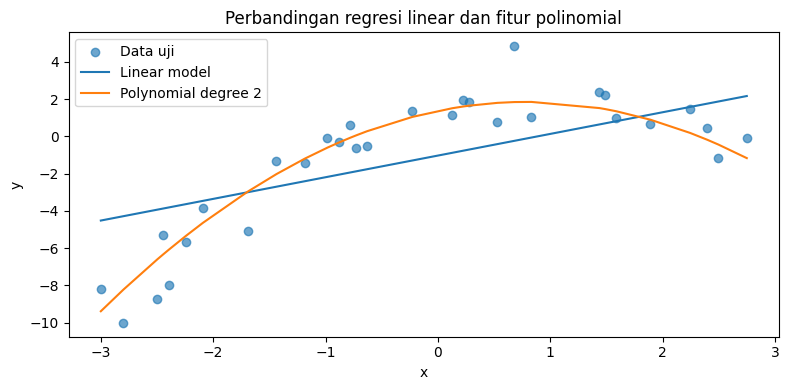

In [21]:
order = np.argsort(X_curve_test[:, 0])
plt.figure(figsize=(8, 4))
plt.scatter(X_curve_test[:, 0], y_curve_test, alpha=0.65, label="Data uji")
plt.plot(X_curve_test[order, 0], linear_pred[order], label="Linear model")
plt.plot(X_curve_test[order, 0], poly_pred[order], label="Polynomial degree 2")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Perbandingan regresi linear dan fitur polinomial")
plt.legend()
plt.tight_layout()
plt.show()

### 7.2 `KBinsDiscretizer` untuk mengelompokkan nilai kontinu

Diskretisasi mengganti angka kontinu dengan indeks kelompok (*bin*). Strategi `quantile` menentukan batas berdasarkan kuantil, agar jumlah sampel antarkelompok cenderung serupa bila nilai tidak terlalu banyak berulang.

In [22]:
age_values = pd.DataFrame({"Age": [18, 20, 22, 25, 29, 34, 39, 45, 52, 61, 67, 72]})

try:
    age_binner = KBinsDiscretizer(
        n_bins=3, encode="ordinal", strategy="quantile", subsample=None
    )
except TypeError:
    # Fallback untuk versi yang tidak memiliki parameter subsample.
    age_binner = KBinsDiscretizer(
        n_bins=3, encode="ordinal", strategy="quantile"
    )

age_bin_codes = age_binner.fit_transform(age_values[["Age"]]).astype(int).ravel()
age_grouped = age_values.assign(Age_Bin=age_bin_codes)
print("Batas bin:", np.round(age_binner.bin_edges_[0], 2))
display(age_grouped)

Batas bin: [18.   27.67 47.33 72.  ]


,Age,Age_Bin
0,18,0
1,20,0
2,22,0
3,25,0
4,29,1
5,34,1
6,39,1
7,45,1
8,52,2
9,61,2


### 7.3 Memilih fitur dengan `RFE`

Feature selection berusaha mempertahankan fitur yang paling membantu prediksi dan mengurangi fitur yang kurang relevan. `RFE` (*Recursive Feature Elimination*) melatih estimator lalu menghapus fitur dengan peringkat rendah secara bertahap sampai jumlah fitur yang diinginkan tercapai.

In [23]:
X_reg, y_reg = make_regression(
    n_samples=220,
    n_features=8,
    n_informative=4,
    noise=12,
    random_state=RANDOM_STATE
)
reg_feature_names = [f"feature_{i+1}" for i in range(X_reg.shape[1])]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=RANDOM_STATE
)

rfe_selector = RFE(
    estimator=LinearRegression(),
    n_features_to_select=4
)
rfe_selector.fit(Xr_train, yr_train)

rfe_results = pd.DataFrame({
    "Feature": reg_feature_names,
    "Ranking": rfe_selector.ranking_,
    "Selected": rfe_selector.support_
}).sort_values(["Ranking", "Feature"])

display(rfe_results.reset_index(drop=True))

,Feature,Ranking,Selected
0,feature_1,1,True
1,feature_4,1,True
2,feature_7,1,True
3,feature_8,1,True
4,feature_3,2,False
5,feature_2,3,False
6,feature_5,4,False
7,feature_6,5,False


### 7.4 `SelectFromModel`: memilih fitur berdasarkan kepentingan

`SelectFromModel` melatih sebuah estimator yang memiliki ukuran kepentingan fitur, lalu memilih fitur yang memenuhi ambang yang ditentukan. Contoh berikut memakai Random Forest untuk regresi, yang menyediakan `feature_importances_`. Tidak ada jaminan bahwa subset terpilih selalu meningkatkan kinerja; bandingkan model menggunakan evaluasi yang adil.

In [24]:
importance_selector = SelectFromModel(
    estimator=RandomForestRegressor(
        n_estimators=120, random_state=RANDOM_STATE
    ),
    threshold="median"
)
importance_selector.fit(Xr_train, yr_train)

forest_estimator = importance_selector.estimator_
importance_results = pd.DataFrame({
    "Feature": reg_feature_names,
    "Importance": forest_estimator.feature_importances_,
    "Selected": importance_selector.get_support()
}).sort_values("Importance", ascending=False)

display(importance_results.reset_index(drop=True))
print("Jumlah fitur terpilih:", int(importance_selector.get_support().sum()))

,Feature,Importance,Selected
0,feature_1,0.507746,True
1,feature_7,0.207762,True
2,feature_8,0.186786,True
3,feature_4,0.036076,True
4,feature_5,0.018827,False
5,feature_2,0.015603,False
6,feature_3,0.015356,False
7,feature_6,0.011845,False


Jumlah fitur terpilih: 4


In [25]:
Xr_train_selected = importance_selector.transform(Xr_train)
Xr_test_selected = importance_selector.transform(Xr_test)

selected_model = RandomForestRegressor(
    n_estimators=120, random_state=RANDOM_STATE
)
selected_model.fit(Xr_train_selected, yr_train)
selected_predictions = selected_model.predict(Xr_test_selected)

baseline_model = RandomForestRegressor(
    n_estimators=120, random_state=RANDOM_STATE
)
baseline_model.fit(Xr_train, yr_train)
baseline_predictions = baseline_model.predict(Xr_test)

print(f"R² Random Forest dengan semua fitur : {r2_score(yr_test, baseline_predictions):.3f}")
print(f"R² Random Forest fitur terpilih     : {r2_score(yr_test, selected_predictions):.3f}")

R² Random Forest dengan semua fitur : 0.743
R² Random Forest fitur terpilih     : 0.813


## 8. Panduan memilih teknik preprocessing

Tidak ada satu teknik preprocessing yang terbaik untuk semua data dan semua algoritma.

- **Nilai kosong:** mulai dengan memahami pola kehilangan data. `SimpleImputer` sering menjadi baseline yang masuk akal.
- **Perbedaan skala:** pertimbangkan scaling khususnya untuk algoritma berbasis jarak atau optimisasi yang sensitif terhadap skala.
- **Kategori tanpa urutan:** `OneHotEncoder` biasanya lebih sesuai daripada memberi kategori angka arbitrer.
- **Fitur numerik dan kategori bercampur:** gunakan `ColumnTransformer`.
- **Banyak langkah preprocessing:** rangkai dengan `Pipeline`, dan latih hanya pada data latih.
- **Relasi nonlinear atau fitur berlebih:** uji feature engineering dan feature selection dengan evaluasi yang konsisten.

Satu teknik yang bekerja baik pada contoh sintetis belum tentu menjadi pilihan terbaik pada dataset nyata.

## 9. Ringkasan Chapter 2

Chapter ini menekankan bahwa pemrosesan data merupakan bagian penting dari workflow machine learning, bukan sekadar pekerjaan tambahan sebelum pelatihan model.

1. Periksa kualitas data mentah dan pahami missing values sebelum memilih strategi.
2. Gunakan `SimpleImputer`, `KNNImputer`, atau `IterativeImputer` berdasarkan kebutuhan dan karakteristik data.
3. Pilih scaler sesuai sifat fitur dan algoritma; `StandardScaler`, `MinMaxScaler`, `RobustScaler`, dan `Normalizer` mempunyai tujuan yang berbeda.
4. Gunakan encoding yang sesuai: one-hot untuk nominal, ordinal untuk kategori yang memang mempunyai urutan, dan `LabelEncoder` terutama untuk target.
5. Terapkan transformasi berbeda pada kolom yang berbeda melalui `ColumnTransformer`.
6. Gunakan `Pipeline` untuk menggabungkan preprocessing dan model serta membantu mencegah *data leakage*.
7. Feature engineering dapat membuat pola lebih mudah dipelajari, sedangkan feature selection dapat mengurangi jumlah masukan. Keduanya perlu dievaluasi, bukan diasumsikan selalu meningkatkan model.

### Referensi

John Sukup, *scikit-learn Cookbook*, Third Edition, Packt Publishing, Chapter 2: “Pre-Model Workflow and Data Preprocessing”.

Kode menggunakan API publik NumPy, pandas, Matplotlib, dan scikit-learn. Untuk latihan, jalankan sel secara berurutan dari atas ke bawah, kemudian ubah beberapa parameter dan amati perbedaannya.